<a href="https://colab.research.google.com/github/davischub/bank-marketing-analytics/blob/main/notebooks/01_analise_exploratoria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise exploratória de campanhas bancárias

**Objetivo:** entender a base pública UCI Bank Marketing, avaliar a qualidade das informações e investigar como a adesão a depósitos a prazo varia entre perfis de clientes.

**Como estudar:** leia a explicação antes de cada célula, observe o resultado e tente responder: *o que queríamos descobrir e por que fizemos esse cálculo?*

> Os dados são de campanhas de uma instituição portuguesa, e não do Itaú. A variável `y` representa adesão, não inadimplência.


### Preparando o ambiente

Antes de analisar os dados, importamos as bibliotecas: `pandas` para trabalhar com tabelas, `numpy` para cálculos e `matplotlib`/`seaborn` para gráficos. Ainda não alteramos nenhuma informação da base.


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


### Carregando o CSV original

Agora lemos o arquivo `bank-additional-full.csv` que foi enviado ao Colab. O `sep=';'` informa que as colunas do arquivo são separadas por ponto e vírgula. O resultado fica guardado em `df`, nossa tabela de trabalho. **Atenção:** o CSV precisa estar disponível em `/content/` nesta sessão.


In [11]:
df = pd.read_csv(
    '/content/bank-additional-full.csv',
    sep=';'
)

print("Base carregada com sucesso!")

Base carregada com sucesso!


### Primeiro contato com a tabela

Antes de limpar ou calcular indicadores, precisamos entender como os dados estão organizados. `df.head()` mostra as primeiras linhas e `.T` transpõe a visualização, facilitando enxergar as muitas colunas.


In [12]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

display(df.head().T)

,0,1,2,3,4
age,56,57,37,40,56
job,housemaid,services,services,admin.,services
marital,married,married,married,married,married
education,basic.4y,high.school,high.school,basic.6y,high.school
default,no,unknown,no,no,no
housing,no,no,yes,no,no
loan,no,no,no,no,yes
contact,telephone,telephone,telephone,telephone,telephone
month,may,may,may,may,may
day_of_week,mon,mon,mon,mon,mon


### Verificando possíveis problemas

Procuramos valores realmente ausentes com `isnull()` e linhas exatamente repetidas com `duplicated()`. Essa etapa evita fazer análises sem conhecer a qualidade dos dados. Um texto como `unknown` não é contado como valor nulo.


In [13]:
print("Valores ausentes por coluna:")
display(df.isnull().sum())

print("Quantidade de registros duplicados:")
print(df.duplicated().sum())


Valores ausentes por coluna:


,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


Quantidade de registros duplicados:
12


### Investigando os registros repetidos

Antes de excluir qualquer linha, visualizamos as que aparecem repetidas. Isso ajuda a conferir o problema. Como a base não traz um identificador único de contato, **registros iguais não garantem contatos duplicados**; a remoção é uma decisão de tratamento que precisa ser documentada.


In [14]:
duplicados = df[df.duplicated(keep=False)]

print(f"Registros envolvidos em duplicações: {len(duplicados)}")

display(duplicados.sort_values(by=list(df.columns)))

Registros envolvidos em duplicações: 24


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


### Identificando respostas desconhecidas

Algumas informações não estão vazias, mas aparecem literalmente como `unknown` (desconhecido). O laço `for` percorre as colunas de texto e conta essas ocorrências, mostrando onde há limitações para interpretar os perfis.


In [15]:
for coluna in df.select_dtypes(include='object').columns:
    quantidade = (df[coluna] == 'unknown').sum()

    if quantidade > 0:
        print(f"{coluna}: {quantidade} registros desconhecidos")

job: 330 registros desconhecidos
marital: 80 registros desconhecidos
education: 1731 registros desconhecidos
default: 8597 registros desconhecidos
housing: 990 registros desconhecidos
loan: 990 registros desconhecidos


### Aplicando a regra de remoção de duplicados

Usamos `drop_duplicates()` para manter somente uma ocorrência de cada linha exatamente igual. Comparamos as quantidades antes e depois. Essa é uma escolha metodológica do estudo, não uma comprovação de que os contatos eram indevidos.


In [16]:
print(f"Registros antes: {len(df)}")

df = df.drop_duplicates()

print(f"Registros depois: {len(df)}")
print(f"Duplicados restantes: {df.duplicated().sum()}")

Registros antes: 41188
Registros depois: 41176
Duplicados restantes: 0


### Medindo o impacto dos dados desconhecidos

Agora calculamos **quantidade e percentual** de `unknown` em campos importantes, como profissão, escolaridade e histórico de crédito. O percentual facilita comparar colunas com números de ocorrências diferentes.


In [17]:
for coluna in ['job', 'marital', 'education',
               'default', 'housing', 'loan']:

    qtd = (df[coluna] == 'unknown').sum()
    percentual = (qtd / len(df)) * 100

    print(f"{coluna}: {qtd} ({percentual:.2f}%)")

job: 330 (0.80%)
marital: 80 (0.19%)
education: 1730 (4.20%)
default: 8596 (20.88%)
housing: 990 (2.40%)
loan: 990 (2.40%)


### Conhecendo os números da base

`describe()` resume as variáveis numéricas, mostrando contagem, média, desvio-padrão, mínimos, quartis e máximos. Isso nos dá uma visão inicial das distribuições antes de construir gráficos.


In [18]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41176.00000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000,41176.000000
mean,40.02380,258.315815,2.567879,962.464810,0.173013,0.081922,93.575720,-40.502863,3.621293,5167.034870
std,10.42068,259.305321,2.770318,186.937102,0.494964,1.570883,0.578839,4.627860,1.734437,72.251364
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


### Documentando a estrutura dos dados

Criamos uma tabela-resumo com nome de cada coluna, tipo de dado, quantidade de nulos e quantidade de valores distintos. Assim sabemos quais variáveis podem ser usadas para cálculos e quais representam categorias.


In [19]:
estrutura = pd.DataFrame({
    'coluna': df.columns,
    'tipo': df.dtypes.astype(str).values,
    'nulos': df.isnull().sum().values,
    'valores_unicos': df.nunique().values
})

display(estrutura)

,coluna,tipo,nulos,valores_unicos
0,age,int64,0,78
1,job,object,0,12
2,marital,object,0,4
3,education,object,0,8
4,default,object,0,3
5,housing,object,0,3
6,loan,object,0,3
7,contact,object,0,2
8,month,object,0,10
9,day_of_week,object,0,5


### Explorando as categorias

Para as colunas de texto, contamos quantas vezes cada resposta aparece usando `value_counts()`. Isso ajuda a descobrir, por exemplo, a composição por profissão e as categorias mais frequentes.


In [20]:
colunas_categoricas = df.select_dtypes(
    include='object'
).columns

for coluna in colunas_categoricas:
    print(f"\nCOLUNA: {coluna}")
    print(df[coluna].value_counts())


COLUNA: job
job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

COLUNA: marital
marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64

COLUNA: education
education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64

COLUNA: default
default
no         32577
unknown     8596
yes            3
Name: count, dtype: int64

COLUNA: housing
housing
yes        21571
no         18615
unknown      990
Name: count, dtype: int64

COLUNA: loan
loan
no         33938
yes         6248
unknown      9

### Encontrando as adesões

A coluna `y` indica o resultado da campanha: `yes` para adesão e `no` para não adesão. Filtramos os registros `yes` para saber quantas adesões ocorreram. **Não estamos analisando inadimplência** nesta base.


In [21]:
clientes_aderiram = df[df['y'] == 'yes']

print(f"Registros com adesão: {len(clientes_aderiram)}")

display(clientes_aderiram.head())

Registros com adesão: 4639


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
75,41,blue-collar,divorced,basic.4y,unknown,yes,no,telephone,may,mon,1575,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,yes
83,49,entrepreneur,married,university.degree,unknown,yes,no,telephone,may,mon,1042,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,yes
88,49,technician,married,basic.9y,no,no,no,telephone,may,mon,1467,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,yes
129,41,technician,married,professional.course,unknown,yes,no,telephone,may,mon,579,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,yes
139,45,blue-collar,married,basic.9y,unknown,yes,no,telephone,may,mon,461,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,yes


### Criando o principal indicador comercial

A **taxa de adesão** é a quantidade de registros com `y = yes` dividida pelo total de registros, multiplicada por 100. Esse percentual serve como referência para comparar segmentos da campanha.


In [22]:
total_registros = len(df)

total_adesoes = len(clientes_aderiram)

taxa_adesao = (total_adesoes / total_registros) * 100

print(f"Taxa geral de adesão: {taxa_adesao:.2f}%")

Taxa geral de adesão: 11.27%


### Comparando a taxa por profissão

Agrupamos os registros pela coluna `job` e calculamos, para cada profissão, a proporção que respondeu `yes`. Ordenar as taxas ajuda a identificar segmentos que tiveram maior adesão proporcional.


In [23]:
adesao_por_profissao = (
    df.groupby('job')['y']
    .apply(lambda coluna: (coluna == 'yes').mean() * 100)
    .sort_values(ascending=False)
)

display(adesao_por_profissao.round(2))

,y
job,
student,31.43
retired,25.26
unemployed,14.20
admin.,12.97
management,11.22
unknown,11.21
technician,10.83
self-employed,10.49
housemaid,10.00


### Transformando as taxas em um gráfico

O gráfico de barras facilita comparar visualmente as taxas entre profissões. A porcentagem é mais útil para essa comparação do que olhar apenas o total de adesões, porque os tamanhos dos grupos são diferentes.


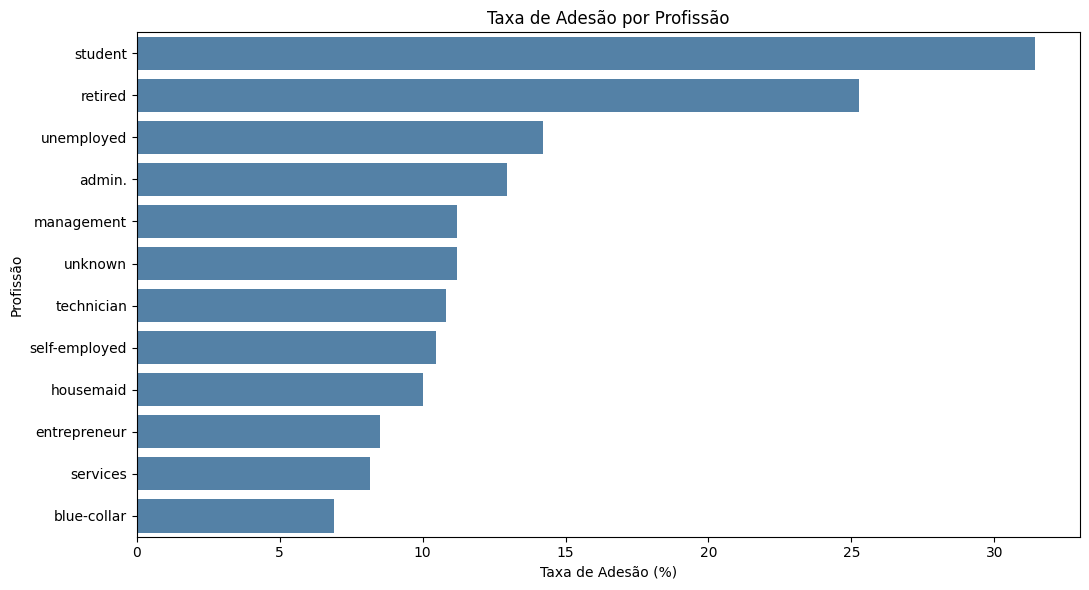

In [24]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=adesao_por_profissao.values,
    y=adesao_por_profissao.index,
    color='steelblue'
)

plt.title('Taxa de Adesão por Profissão')
plt.xlabel('Taxa de Adesão (%)')
plt.ylabel('Profissão')

plt.tight_layout()
plt.show()

### Separando volume e conversão

Criamos uma tabela com três medidas por profissão: **total de registros, número de adesões e taxa de adesão**. Um grupo pode ter taxa alta, mas poucos registros; outro pode gerar mais adesões em quantidade.


In [25]:
resumo_profissoes = (
    df.groupby('job')['y']
    .agg(
        total='count',
        adesoes=lambda x: (x == 'yes').sum()
    )
)

resumo_profissoes['taxa_adesao'] = (
    resumo_profissoes['adesoes']
    / resumo_profissoes['total'] * 100
)

display(
    resumo_profissoes.sort_values(
        'taxa_adesao',
        ascending=False
    ).round(2)
)

,total,adesoes,taxa_adesao
job,,,
student,875,275,31.43
retired,1718,434,25.26
unemployed,1014,144,14.20
admin.,10419,1351,12.97
management,2924,328,11.22
unknown,330,37,11.21
technician,6739,730,10.83
self-employed,1421,149,10.49
housemaid,1060,106,10.00


### Comparando cada profissão com a média geral

Calculamos a diferença entre a taxa de cada profissão e a taxa geral, em **pontos percentuais**. Por exemplo, uma taxa de 15% contra média de 11% representa uma diferença de 4 pontos percentuais, não 4%.


In [26]:
taxa_geral = (df['y'] == 'yes').mean() * 100

resumo_profissoes['dif_media_pp'] = (
    resumo_profissoes['taxa_adesao'] - taxa_geral
)

display(
    resumo_profissoes.sort_values(
        'dif_media_pp',
        ascending=False
    ).round(2)
)

,total,adesoes,taxa_adesao,dif_media_pp
job,,,,
student,875,275,31.43,20.16
retired,1718,434,25.26,14.00
unemployed,1014,144,14.20,2.93
admin.,10419,1351,12.97,1.70
management,2924,328,11.22,-0.05
unknown,330,37,11.21,-0.05
technician,6739,730,10.83,-0.43
self-employed,1421,149,10.49,-0.78
housemaid,1060,106,10.00,-1.27


A análise de 41.176 registros de campanhas bancárias identificou uma taxa geral de adesão de 11,27%, com diferenças relevantes entre grupos profissionais. Estudantes e aposentados apresentaram taxas superiores à média, enquanto profissionais administrativos concentraram o maior volume absoluto de contratações. Os resultados indicam oportunidades para aprofundar estudos de segmentação e eficiência comercial.

### Entendendo a distribuição de idades

O histograma mostra quantos registros se concentram em determinadas idades. Antes de comparar adesão, é importante descobrir qual é o perfil etário mais presente na amostra.


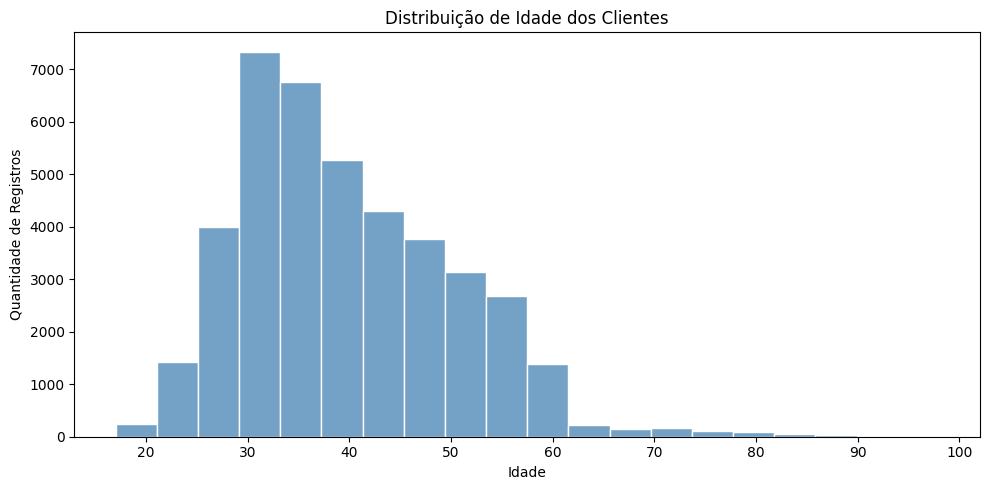

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='age',
    bins=20,
    color='steelblue',
    edgecolor='white'
)

plt.title('Distribuição de Idade dos Clientes')
plt.xlabel('Idade')
plt.ylabel('Quantidade de Registros')

plt.tight_layout()
plt.show()

### Comparando idade entre quem aderiu e quem não aderiu

O **boxplot** resume a distribuição de idade nos dois grupos (`yes` e `no`), exibindo mediana e dispersão. Ele não prova que a idade causa a adesão; apenas ajuda a observar possíveis diferenças.


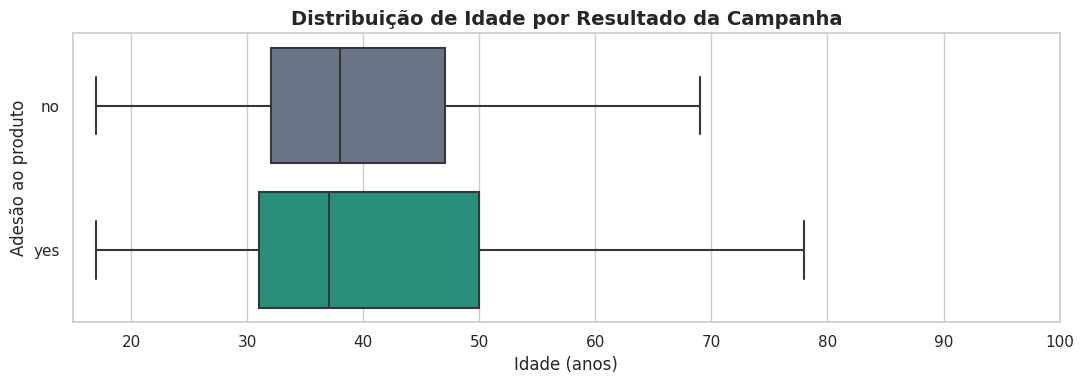

In [30]:
plt.figure(figsize=(11, 4))

sns.set_theme(style="whitegrid")

sns.boxplot(
    data=df,
    x='age',
    y='y',
    order=['no', 'yes'],
    hue='y',
    hue_order=['no', 'yes'],
    palette={
        'no': '#64748B',
        'yes': '#16A085'
    },
    showfliers=False,
    linewidth=1.5,
    legend=False
)

plt.title(
    'Distribuição de Idade por Resultado da Campanha',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Idade (anos)')
plt.ylabel('Adesão ao produto')

plt.xlim(15, 100)
plt.tight_layout()
plt.show()

### Criando segmentos etários e calculando adesão

Usamos `pd.cut()` para transformar idades individuais em faixas, como `30-39` e `40-49`. Depois agrupamos por faixa e calculamos totais, adesões e taxas. Isso torna a análise mais fácil de comunicar comercialmente.


In [29]:
df['faixa_etaria'] = pd.cut(
    df['age'],
    bins=[0, 29, 39, 49, 59, 69, float('inf')],
    labels=[
        'Até 29',
        '30-39',
        '40-49',
        '50-59',
        '60-69',
        '70+'
    ]
)

resumo_idade = (
    df.groupby('faixa_etaria', observed=True)['y']
    .agg(
        total='count',
        adesoes=lambda x: (x == 'yes').sum()
    )
)

resumo_idade['taxa_adesao'] = (
    resumo_idade['adesoes'] /
    resumo_idade['total'] * 100
)

display(resumo_idade.round(2))


,total,adesoes,taxa_adesao
faixa_etaria,,,
Até 29,5667,922,16.27
30-39,16933,1715,10.13
40-49,10523,833,7.92
50-59,6861,697,10.16
60-69,724,251,34.67
70+,468,221,47.22


### Conferindo a categorização das idades

Esta célula recria as mesmas faixas etárias e mostra dez exemplos, lado a lado com a idade original. É uma conferência didática: a definição já havia sido aplicada acima.


In [31]:
df['faixa_etaria'] = pd.cut(
    df['age'],
    bins=[0, 29, 39, 49, 59, 69, float('inf')],
    labels=['Até 29', '30-39', '40-49', '50-59', '60-69', '70+']
)

df[['age', 'faixa_etaria']].head(10)

,age,faixa_etaria
0,56,50-59
1,57,50-59
2,37,30-39
3,40,40-49
4,56,50-59
5,45,40-49
6,59,50-59
7,41,40-49
8,24,Até 29
9,25,Até 29


### Recalculando o resumo por faixa etária

Repetimos o agrupamento para exibir, de forma direta, o número de registros, as adesões e as taxas de cada faixa. É uma etapa de conferência e apresentação; a análise já havia sido calculada anteriormente.


In [32]:
resumo_idade = (
    df.groupby('faixa_etaria', observed=True)['y']
    .agg(
        total='count',
        adesoes=lambda x: (x == 'yes').sum()
    )
)

resumo_idade['taxa_adesao'] = (
    resumo_idade['adesoes'] /
    resumo_idade['total'] * 100
)

display(resumo_idade.round(2))

,total,adesoes,taxa_adesao
faixa_etaria,,,
Até 29,5667,922,16.27
30-39,16933,1715,10.13
40-49,10523,833,7.92
50-59,6861,697,10.16
60-69,724,251,34.67
70+,468,221,47.22


### Visualizando a adesão por faixa etária

O gráfico final apresenta a taxa de adesão de cada faixa com percentuais escritos sobre as barras. A visualização ajuda a enxergar diferenças, mas não permite concluir causalidade nem garantir que o resultado se repetirá em campanhas futuras.


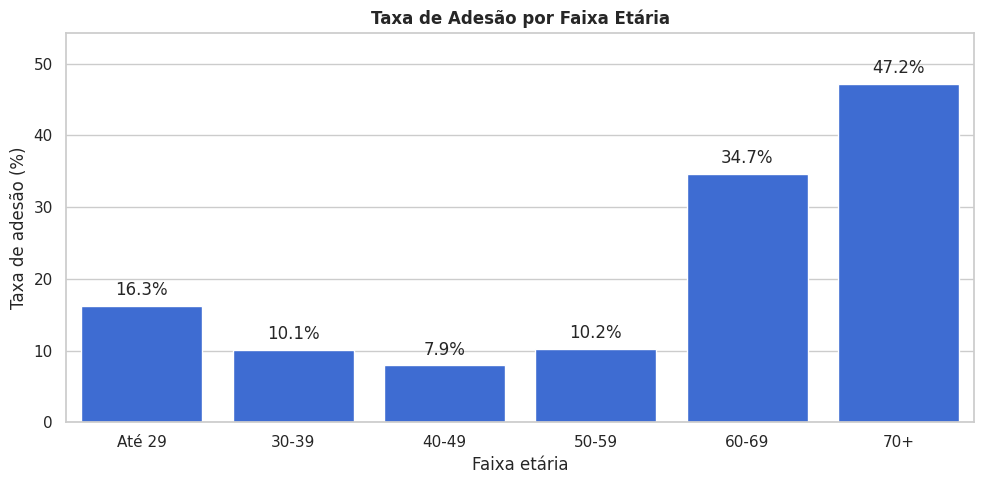

In [33]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=resumo_idade.reset_index(),
    x='faixa_etaria',
    y='taxa_adesao',
    color='#2563EB'
)

for barra in ax.patches:
    altura = barra.get_height()

    ax.annotate(
        f'{altura:.1f}%',
        (barra.get_x() + barra.get_width() / 2, altura),
        ha='center',
        va='bottom',
        xytext=(0, 5),
        textcoords='offset points'
    )

plt.title('Taxa de Adesão por Faixa Etária', fontweight='bold')
plt.xlabel('Faixa etária')
plt.ylabel('Taxa de adesão (%)')
plt.ylim(0, resumo_idade['taxa_adesao'].max() * 1.15)

plt.tight_layout()
plt.show()